# Paired cross-modal trajectories

Run each cell in order after installing COATI. Each training run creates a fresh output directory. Synthetic examples test functionality; they are not biological benchmarks.

## 1. Import

In [1]:
import coati as ct
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


## 2. Generate and inspect data

In [2]:
data = ct.datasets.paired(n=128, seed=0)
print("Times:", data.times)
print("Primary shapes:", [x.shape for x in data.primary])
print("Secondary shapes:", None if data.secondary is None else [x.shape for x in data.secondary])

Times: [0.  0.5 1. ]
Primary shapes: [(128, 2), (128, 2), (128, 2)]
Secondary shapes: [(128, 3), (128, 3), (128, 3)]


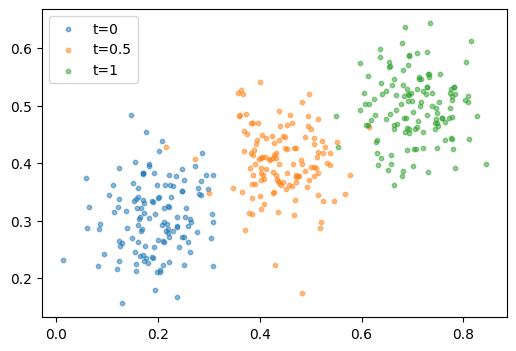

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
for t, x in zip(data.times, data.primary):
    ax.scatter(x[:, 0], x[:, 1], s=10, alpha=.5, label=f"t={t:g}")
ax.legend()
plt.show()

## 3. Choose explicit training settings

The default synchronized run trains a paired FiLM map before fitting the flow. Use `map_type='mlp'` in Config for a map without time input. Pass `T_model=my_map` to reuse your own trained map. To omit the middle stage from both map and trajectory fitting, use `training_data = data.without_times([0.5])`; retain the original time coordinates.

In [4]:
config = ct.Config(niters=200, seed=0, sync_loss=True, sync_weight=0.35)
config.to_dict()

{'time_plot': False,
 'reverseMatching': False,
 'accumulate_training': True,
 'MixSampling': False,
 'seed': 0,
 'gpu': 0,
 'unbalancedModel': False,
 'alpha_growth': 0.0,
 'mass_loss': False,
 'mass_coefficient': 0.0,
 'global_mass': False,
 'hidden_dim': 64,
 'n_layers': 2,
 'activation': 'leaky_relu',
 'niters': 200,
 'lr': 0.001,
 'num_samples': 64,
 'median_n_sample': 128,
 'floor_n_sample': 64,
 'support_points': False,
 'dt': 0.1,
 'mmd_loss': False,
 'density_coefficient': 0.0,
 'pdf_lossMSE': False,
 'pdf_coefficient': 50.0,
 'sinkhorn_pdf': True,
 'energy_coefficient': 1.0,
 'density_topk': 25,
 'density_hinge': 0.01,
 'terminal_density_weight': 1.0,
 'sync_loss': True,
 'sync_weight': 0.35,
 'sync_mmd_loss': False,
 'sync_density_loss': False,
 'sync_pdf_loss': True,
 'map_type': 'film',
 'kernel_sigma': 0.01,
 'adaptive_lambda': False,
 'blur_coeff': 0.05,
 'floor_buffer_std': 0.0,
 'lambda_max_pri': 100.0,
 'lambda_max_sec': 100.0,
 'lambda_min_pri': 5.0,
 'lambda_min_sec

## 4. Train

In [5]:
training_data = data
result = ct.fit(training_data, config)
print(result.output_dir)
print(result.map_report['status'])
print((result.output_dir / 'map/report.txt').read_text())

/Users/jingfeng/local/project/COATI/notebooks/outputs/run-4b0bf1644b
passed
COATI film map validation: passed
Best epoch: 300
Paired cells withheld within supplied stages; also used for checkpoint selection. Not an independent test of unseen stages or cell-type alignment.

Stage	Time	Train	Validation	Paired RMSE	Normalized MSE	Sinkhorn	Split floor
t0	0.0	102	26	0.0007092795250050058	0.0002101751457179184	6.187894996401155e-07	0.0021591474302113055
t1	0.5	102	26	0.0018371087687239936	0.0009906818126734715	5.713064228984876e-06	0.0026746366638690233
t2	1.0	102	26	0.0005581328268770357	0.0001218253693658433	4.0742700093687743e-07	0.0016568288672715425




## 5. Integrate trajectories

In [6]:
trajectory = result.predict()
print(trajectory["primary"].shape)
assert np.isfinite(trajectory["primary"]).all()

(41, 128, 2)


## 6. Inspect metrics and trajectories

Energy is in training units; these toy arrays have not been W2-normalized. Endpoint Sinkhorn is an unweighted geometric diagnostic, including in the growth example.

In [7]:
metrics = result.evaluate()
metrics

{'endpoint_sinkhorn_before': 0.14770656824111938,
 'endpoint_sinkhorn_after': 0.00036481721326708794,
 'kinetic_energy_mean': 0.14290177822113037,
 'endpoint_sampling_floor': 0.0002629088703542948,
 'secondary_endpoint_sinkhorn': 0.00038335530553013086}

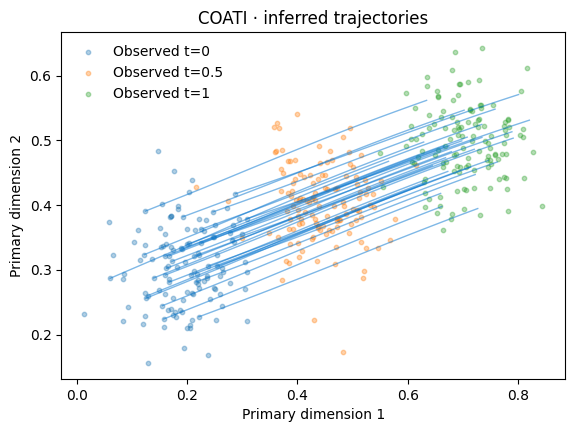

In [8]:
result.plot()
plt.show()

## Secondary trajectories

Prediction uses the same frozen FiLM map that constrained trajectory fitting. Validation reports describe cells reserved within the supplied stages, not accuracy at an omitted stage. The map and all its normalization buffers are saved automatically.

In [9]:
secondary = result.project_secondary(trajectory)
print(secondary.shape)
assert secondary.shape[-1] == 3

(41, 128, 3)


## 7. Reload the saved model

In [10]:
restored = ct.load_result(result.output_dir)
np.testing.assert_array_equal(restored.predict()["primary"], trajectory["primary"])
np.testing.assert_array_equal(restored.project_secondary(), secondary)
print("Reload reproduces RNA and ATAC trajectories exactly.")

Reload reproduces RNA and ATAC trajectories exactly.
